# Colab Intro

Notebook prezentujący podstawowe obliczenia w Pythonie,
tworzenie wykresów, generowanie animacji oraz krzywych parametrycznych.

## Sumowanie ciągu geometrycznego

Ciąg geometryczny to ciąg liczb, w którym każdy kolejny wyraz
otrzymujemy przez pomnożenie poprzedniego przez stały iloraz *q*.

Suma pierwszych *n* wyrazów ciągu geometrycznego, dla *q* &ne;1,
jest opisana wzorem:

$$
S_n = a_1 \frac{1-q^n}{1-q}
$$

gdzie:

- *S<sub>n</sub>* — suma pierwszych \(n\) wyrazów,
- *a<sub>1</sub>* — pierwszy wyraz ciągu,
- *q* — iloraz ciągu,
- *n* — liczba wyrazów.

**Przykład:** dla *a<sub>1</sub>*=2, *q=3* i *n*=5:

$$
S_5 = 2 \cdot \frac{1-3^5}{1-3}=242
$$

W Pythonie możemy obliczyć tę sumę za pomocą pętli lub wzoru.

In [ ]:
wynik = 2 + 2
print("2 + 2 =", wynik)

2 + 2 = 4


In [ ]:
import math

wynik = math.pi ** math.pi
print("π**π =", wynik)

π**π = 36.4621596072079


In [ ]:
suma_kwadratow = sum(k**2 for k in range(1, 101))
print("Suma kwadratów liczb od 1 do 100:", suma_kwadratow)

Suma kwadratów liczb od 1 do 100: 338350


In [ ]:
with open("colab_wynik.txt", "w", encoding="utf-8") as plik:
  plik.write(f"Suma kwadratów liczb od 1 do 100: {suma_kwadratow}\n")

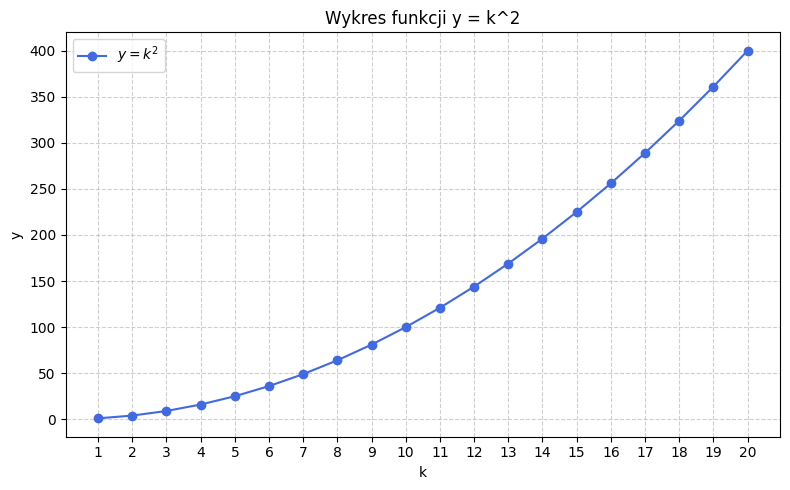

Wykres zapisano w /content/wykres.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
k = np.arange(1,21)
y = k**2

plt.figure(figsize=(8,5))
plt.plot(k, y, marker="o", color="royalblue", label=r"$y=k^2$")
plt.title("Wykres funkcji y = k^2")
plt.xlabel("k")
plt.ylabel("y")
plt.xticks(k)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()

plt.savefig("/content/wykres.png", dpi=150, bbox_inches="tight")
plt.show()

print("Wykres zapisano w /content/wykres.png")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import Video, display
import shutil
import subprocess
import sys

# Sprawdzenie dostępności FFmpeg
if shutil.which("ffmpeg") is None:
    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "ffmpeg"],
        check=True
    )

# Parametry animacji
g = 9.81
dlugosc = 1.0
kat_poczatkowy = np.radians(40)
omega = np.sqrt(g / dlugosc)

czas = np.linspace(0, 10, 200)
kat = kat_poczatkowy * np.cos(omega * czas)

x = dlugosc * np.sin(kat)
y = -dlugosc * np.cos(kat)

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 0.3)
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.set_title("Animacja wahadła matematycznego")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")

# Punkt zawieszenia
ax.plot(0, 0, "ko", markersize=7)

# Nić i ciężarek
nic, = ax.plot([], [], "b-", linewidth=2)
ciezarek, = ax.plot([], [], "ro", markersize=15)

def init():
    nic.set_data([], [])
    ciezarek.set_data([], [])
    return nic, ciezarek

def update(i):
    nic.set_data([0, x[i]], [0, y[i]])
    ciezarek.set_data([x[i]], [y[i]])
    return nic, ciezarek

animacja = FuncAnimation(
    fig,
    update,
    frames=len(czas),
    init_func=init,
    interval=50,
    blit=True
)

sciezka_video = "/content/video.mp4"

animacja.save(
    sciezka_video,
    writer=FFMpegWriter(fps=20, bitrate=1800)
)

plt.close(fig)

print("Zapisano animację:", sciezka_video)

# Wyświetlenie wideo w notebooku
display(Video(sciezka_video, embed=True, width=600))

Zapisano animację: /content/video.mp4


Zapisano GIF: /content/video.gif
Rozmiar pliku: 153.8 KB


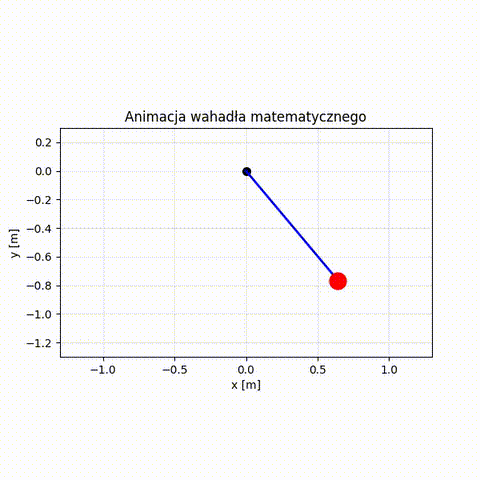

In [ ]:
from pathlib import Path
from IPython.display import Image, display
import subprocess
import shutil

video_path = Path("/content/video.mp4")
gif_path = Path("/content/video.gif")

if not video_path.exists():
    raise FileNotFoundError(
        "Nie znaleziono /content/video.mp4. Uruchom najpierw komórkę 8."
    )

if shutil.which("ffmpeg") is None:
    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "ffmpeg"],
        check=True
    )

subprocess.run(
    [
        "ffmpeg", "-y",
        "-i", str(video_path),
        "-vf", "fps=12,scale=480:-1:flags=lanczos",
        "-loop", "0",
        str(gif_path)
    ],
    check=True
)

print("Zapisano GIF:", gif_path)
print(f"Rozmiar pliku: {gif_path.stat().st_size / 1024:.1f} KB")

display(Image(filename=str(gif_path)))

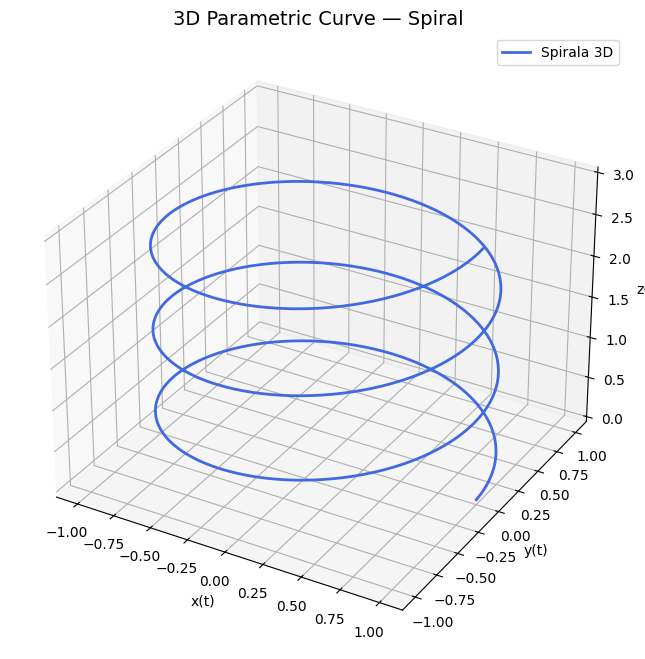

Wykres zapisano w pliku: /content/parametric_curve.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parametr
t = np.linspace(0, 6 * np.pi, 1000)

# Zmodyfikowane równania parametryczne — spirala 3D
x = np.cos(t)
y = np.sin(t)
z = t / (2 * np.pi)

# Wykres 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, color="royalblue", linewidth=2, label="Spirala 3D")

ax.set_title("3D Parametric Curve — Spiral", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

# Zapis wykresu do pliku
sciezka = "/content/parametric_curve.png"
plt.savefig(sciezka, dpi=200, bbox_inches="tight")

# Wyświetlenie wykresu w notebooku
plt.show()

print(f"Wykres zapisano w pliku: {sciezka}")